In [2]:
import pandas as pd
import os
import random
import time
from sklearn.model_selection import train_test_split
import torch
import torchvision
from torch.utils.data import DataLoader, TensorDataset, Dataset,  WeightedRandomSampler
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold
from tqdm import tqdm
from torchvision import models
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [3]:

!nvidia-smi

Sat Jul 18 13:41:38 2026       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.183.01             Driver Version: 535.183.01   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA RTX A6000               Off | 00000000:01:00.0 Off |                  Off |
| 30%   47C    P8              29W / 300W |   1375MiB / 49140MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [4]:
torch.manual_seed(42)

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [6]:
train_path = '/home/dbtproject/barsha/Image/training_set' 
test_path = '/home/dbtproject/barsha/test set_new'

In [7]:
# Show the paths and their types (use type() on a Python object)
print('type(train_path):', type(train_path))

type(train_path): <class 'str'>


In [8]:
print('The training set consists of ', len(os.listdir(train_path +'/Class0_Graminicola')),
 ' Class1_Graminicola images,', len(os.listdir(train_path + '/Class1_Incognita')), 
 'Class2_Incognita images and ', len(os.listdir(train_path + '/Class2_Javanica')), ' Class3_Javanica images.' )

The training set consists of  139  Class1_Graminicola images, 55 Class2_Incognita images and  83  Class3_Javanica images.


In [9]:
print('The test set consists of ', len(os.listdir(test_path +'/Class1_Incognita')), 
 'Class2_Incognita images and ', len(os.listdir(test_path +'/Class2_Javanica')), ' Class3_Javanica images.' )

The test set consists of  20 Class2_Incognita images and  20  Class3_Javanica images.


In [10]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


In [11]:
import os
import pandas as pd
from PIL import Image

def images_to_dataframe(root_dir, allowed_classes=None):
    rows = []

    # root_dir should contain subfolders (classes)
    for label in os.listdir(root_dir):
        if allowed_classes and label not in allowed_classes:
            continue
        class_path = os.path.join(root_dir, label)
        if not os.path.isdir(class_path):
            continue

        for filename in os.listdir(class_path):
            file_path = os.path.join(class_path, filename)

            # Open the image to get size
            try:
                with Image.open(file_path) as img:
                    width, height = img.size
            except:
                continue
            
            rows.append({
                "filename": filename,
                "path": file_path,
                "label": label,
            
            })

    return pd.DataFrame(rows)


# Example: train and test DataFrames
train_df = images_to_dataframe("/home/dbtproject/barsha/Image/training_set")
test_df = images_to_dataframe(
    "/home/dbtproject/barsha/test set_new",
    allowed_classes=[
        "Class1_Incognita",
        "Class2_Javanica"
    ]
)

print(train_df.head())
print(train_df.shape)
print(test_df.shape)


              filename                                               path  \
0       S-57_PP_4.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   
1       D-30_PP_5.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   
2  D-38_PP_Good_4.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   
3       ES-3_PP_4.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   
4       G-60_PP_4.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   

                label  
0  Class0_Graminicola  
1  Class0_Graminicola  
2  Class0_Graminicola  
3  Class0_Graminicola  
4  Class0_Graminicola  
(277, 3)
(40, 3)


In [12]:
train_df.head()

,filename,path,label
0,S-57_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
1,D-30_PP_5.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
2,D-38_PP_Good_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
3,ES-3_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
4,G-60_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola


In [13]:
train_df['label'].value_counts()


label
Class0_Graminicola    139
Class2_Javanica        83
Class1_Incognita       55
Name: count, dtype: int64

In [14]:
train_df.sample(5)


,filename,path,label
30,J-45_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
126,G-13_PP_1.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
220,Meloidogyne javanica_58.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class2_Javanica
142,Meloidogyne javanica_69.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class2_Javanica
255,Meloidogyne incognita_45.jpeg,/home/dbtproject/barsha/Image/training_set/Cla...,Class1_Incognita


In [15]:
# RANDOM_STATE = 42
# VAL_SIZE = 0.20   # 20% validation

# train_df, val_df = train_test_split(
#     train_df,
#     test_size=VAL_SIZE,
#     stratify=train_df['label'],
#     random_state=RANDOM_STATE
# )

# print("After split:")
# print("Train split counts:\n", train_df['label'].value_counts().sort_index())
# print("Val split counts:\n", val_df['label'].value_counts().sort_index())

 

In [17]:
le = LabelEncoder()
# Fit on training labels and transform train/val/test appropriately
train_df['label'] = le.fit_transform(train_df['label'])
# val_df['label'] = le.transform(val_df['label'])
test_df['label'] = le.transform(test_df['label'])
train_df.head(40)


,filename,path,label
0,S-57_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
1,D-30_PP_5.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
2,D-38_PP_Good_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
3,ES-3_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
4,G-60_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
5,D-38_PP_3.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
6,ES-45_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
7,S-10_PP_2.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
8,G-60_PP_1.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
9,D-85_PP_3.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0


In [19]:
test_df.head(30)


,filename,path,label
0,test_img_59.JPG,/home/dbtproject/barsha/test set_new/Class2_Ja...,2
1,test_img_21.JPG,/home/dbtproject/barsha/test set_new/Class2_Ja...,2
2,test_img_60.JPG,/home/dbtproject/barsha/test set_new/Class2_Ja...,2
3,test_img_51.JPG,/home/dbtproject/barsha/test set_new/Class2_Ja...,2
4,test_img_58.JPG,/home/dbtproject/barsha/test set_new/Class2_Ja...,2
5,test_img_56.JPG,/home/dbtproject/barsha/test set_new/Class2_Ja...,2
6,test_img_53.JPG,/home/dbtproject/barsha/test set_new/Class2_Ja...,2
7,test_img_28.JPG,/home/dbtproject/barsha/test set_new/Class2_Ja...,2
8,test_img_23.JPG,/home/dbtproject/barsha/test set_new/Class2_Ja...,2
9,test_img_55.JPG,/home/dbtproject/barsha/test set_new/Class2_Ja...,2


In [17]:
# train_df = train_df.drop(columns=['label'])
# test_df = test_df.drop(columns=['label'])

In [20]:
train_df.shape

(277, 3)

In [21]:
import pandas as pd

mapping_df = pd.DataFrame({
    "Original_Label": le.classes_,
    "Encoded_Label": le.transform(le.classes_)
})

print(mapping_df)

   Original_Label  Encoded_Label
0               0              0
1               1              1
2               2              2


In [22]:
train_transform = transforms.Compose([
    transforms.Resize(256),  # Resize images to a common size
    transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(),  # Data augmentation
    transforms.RandomVerticalFlip(),  # Data augmentation
    transforms.RandomRotation(degrees=(-10,10)), # Randomly rotate images
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normalize with ImageNet stats
])

val_test_transform = transforms.Compose([
    transforms.Resize((256)),
    transforms.CenterCrop((224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [23]:
class DFImageDataset(Dataset):
    def __init__(self, df, img_col='path', label_col='label', transform=None):
        
        self.df = df.reset_index(drop=True)
        self.img_col = img_col
        self.label_col = label_col
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = row[self.img_col]
        # load image (PIL)
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        else:
            # default
            img = transforms.ToTensor()(img)
        label = int(row[self.label_col])
        return img, label


In [24]:
train_data = DFImageDataset(train_df, img_col='path', label_col='label', transform=train_transform)
test_data  = DFImageDataset(test_df,  img_col='path', label_col='label', transform=val_test_transform)


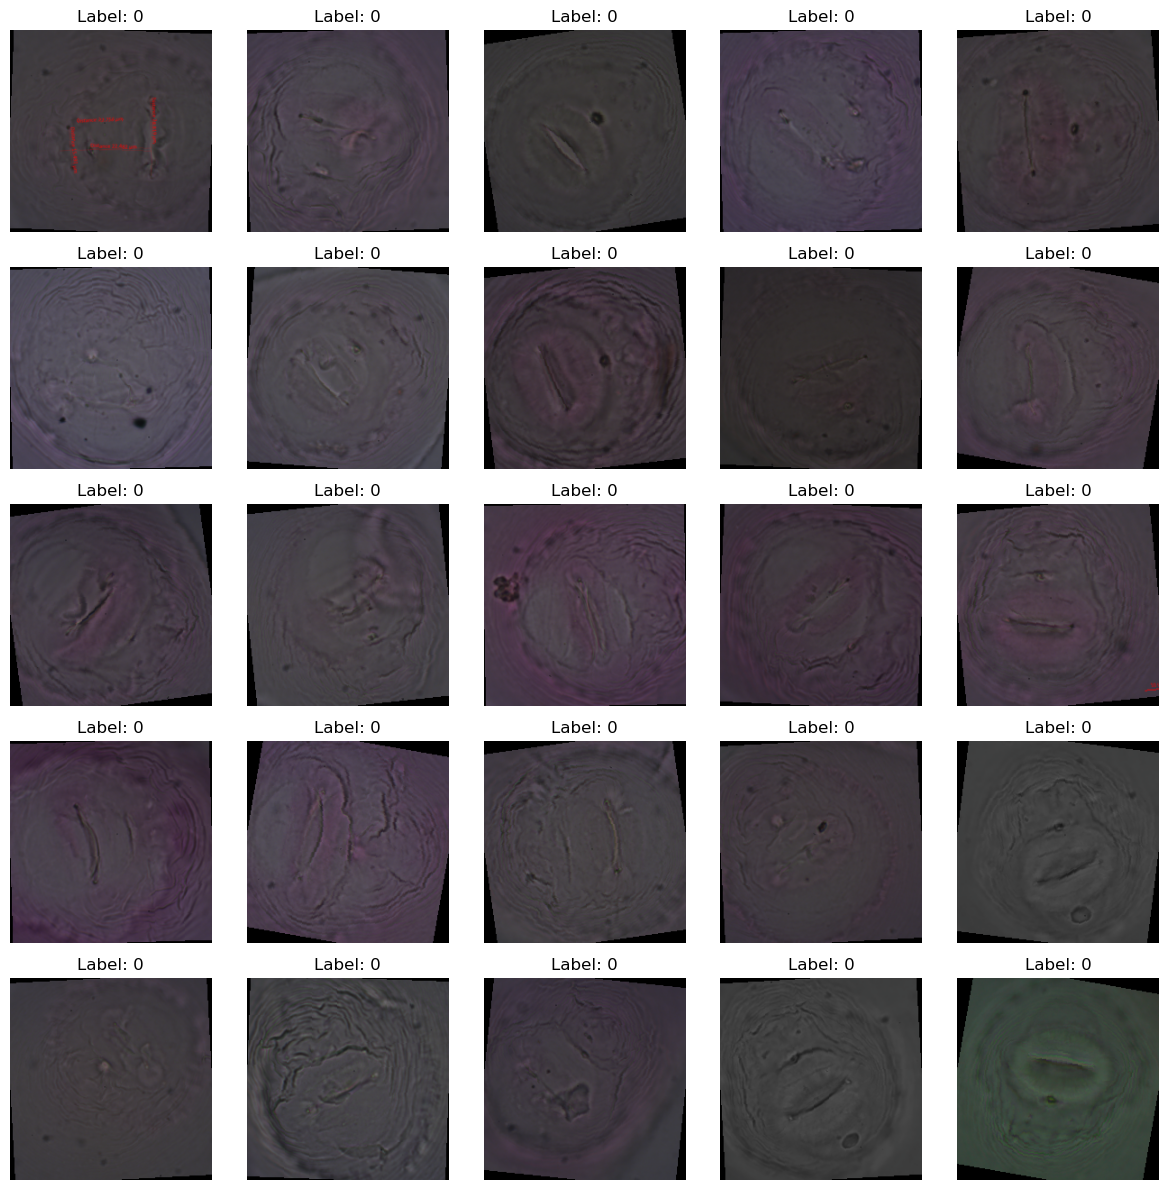

In [25]:
n_rows =5
n_cols =5
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 12))
axes = axes.flatten()
for row in range(n_rows):
    for col in range(n_cols):
        idx = row * n_cols + col
        img, label = train_data[idx]
        img = img.permute(1, 2, 0).numpy()  # Convert from (C, H, W) to (H, W, C)
        img = np.clip(img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]), 0, 1)  # Unnormalize
        axes[idx].imshow(img)
        axes[idx].set_title(f'Label: {label}')
        axes[idx].axis('off')
plt.tight_layout()
plt.show()

In [26]:
#configuration
NUM_EPOCHS = 10
LR = 0.001  #1e-4
BATCH_SIZE = 32
# Eval_batch_size = 16
weight_decay = 0.01
NUM_WORKERS = 4
PIN_MEMORY = True

In [27]:
test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    # num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

In [28]:
NUM_FOLDS = 5
RANDOM_STATE=42

# Create checkpoint folder
CHECKPOINT_DIR = "checkpoints_old_34"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

skf = StratifiedKFold(n_splits=NUM_FOLDS, shuffle=True, random_state=RANDOM_STATE)

all_fold_histories = []
fold_accuracies = []
fold_reports = []
fold_conf_matrices = []
all_fold_histories = []

best_fold = -1
best_fold_acc = 0

for fold, (train_idx, val_idx) in enumerate(skf.split(train_df, train_df['label'])):

    print(f"\n================ FOLD {fold+1}/{NUM_FOLDS} ================\n")

    fold_train_df = train_df.iloc[train_idx].reset_index(drop=True)
    fold_val_df   = train_df.iloc[val_idx].reset_index(drop=True)

    print("Train counts:\n", fold_train_df['label'].value_counts())
    print("Val counts:\n", fold_val_df['label'].value_counts())


    # Dataset
    train_data = DFImageDataset(fold_train_df, img_col='path', label_col='label', transform=train_transform)
    val_data   = DFImageDataset(fold_val_df,   img_col='path', label_col='label', transform=val_test_transform)

    # ---- Weighted Sampler (same logic) ----
    train_labels = fold_train_df['label'].values
    classes, class_counts = np.unique(train_labels, return_counts=True)
    class_weights = {cls: 1.0 / count for cls, count in zip(classes, class_counts)}
    sample_weights = fold_train_df['label'].map(class_weights).values
    sample_weights_tensor = torch.from_numpy(sample_weights.astype(np.float32))

    sampler = WeightedRandomSampler(
        weights=sample_weights_tensor,
        num_samples=len(sample_weights_tensor),
        replacement=True
    )

    # DataLoaders
    train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, sampler=sampler)
    val_loader   = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

    #model 
    model = models.resnet34(weights=models.ResNet34_Weights.DEFAULT)
    in_features = model.fc.in_features
    num_classes = len(le.classes_)  # number of unique labels
    model.fc = nn.Linear(in_features, num_classes)

    for param in model.parameters():
        param.requires_grad = False
    for param in model.fc.parameters():
        param.requires_grad = True

    model.to(device)

    optimizer = optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

    history = {'train_loss': [],
           'val_loss': [],
           'train_accuracy': [],
           'val_accuracy': [],
           'epoch': []}

    best_val_accuracy = 0
    CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    f"best_model_fold_{fold+1}.pth"
    )

    #training loop
    import copy
    import os
    for epoch in range(1, NUM_EPOCHS+1):
        epoch_start = time.time()
        print(f'Epoch {epoch}/{NUM_EPOCHS}')
        
        # Training phase
        model.train()
        running_loss = 0.0
        running_correct = 0
        running_total = 0

        train_bar = tqdm(train_loader, desc=f'Epoch {epoch}/{NUM_EPOCHS} - Training', leave=False)
        for inputs, labels in train_bar:
            inputs, labels = inputs.to(device), labels.to(device)
            batch_size = inputs.size(0)

            optimizer.zero_grad()

            outputs = model(inputs.float())
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * batch_size #(0) #accumulate total loss
            _, predicted = torch.max(outputs, 1)   #take the class with highest score
            running_total += batch_size
            running_correct += (predicted == labels).sum().item() #number of correct predictions

            train_bar.set_postfix(tloss=loss.item(), tacc=(running_correct / running_total) if running_total > 0 else 0)

        ep_tr_loss = running_loss / (running_total if running_total > 0 else 1)
        ep_tr_accuracy = running_correct / (running_total if running_total > 0 else 1)

        # Validation phase
        model.eval()
        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        # all_preds = []
        # all_labels = []

        val_bar = tqdm(val_loader, desc=f'Epoch {epoch}/{NUM_EPOCHS} - Validation', leave=False)
        with torch.no_grad():
            for inputs, labels in val_bar:
                inputs, labels = inputs.to(device), labels.to(device)
                batch_size = inputs.size(0)

                outputs = model(inputs.float())
                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * batch_size
                _, predicted = torch.max(outputs, 1)
                val_total += batch_size
                val_correct += (predicted == labels).sum().item()

                # all_preds.extend(predicted.cpu().numpy())
                # all_labels.extend(labels.cpu().numpy())

                val_bar.set_postfix(vloss=loss.item(), vacc=val_correct/val_total if val_total > 0 else 1)

        ep_val_loss = val_running_loss / (val_total if val_total > 0 else 1)
        ep_val_accuracy = val_correct / (val_total if val_total > 0 else 1)

        # Step the scheduler
        scheduler.step(ep_val_loss)

        # Save history - ensure all lists get one entry per epoch
        history['train_loss'].append(ep_tr_loss)
        history['val_loss'].append(ep_val_loss)
        history['train_accuracy'].append(ep_tr_accuracy)
        history['val_accuracy'].append(ep_val_accuracy)
        history['epoch'].append(epoch)


        epoch_time = time.time() - epoch_start
        print(f"Epoch {epoch}/{NUM_EPOCHS} | train_loss: {ep_tr_loss:.4f} train_acc: {ep_tr_accuracy:.4f} | val_loss: {ep_val_loss:.4f} val_acc: {ep_val_accuracy:.4f} | time: {epoch_time:.1f}s")
    

        # Save the model if validation accuracy improved
        if ep_val_accuracy > best_val_accuracy:
            best_val_accuracy = ep_val_accuracy
            best_model_wts = copy.deepcopy(model.state_dict())
            torch.save({
                    'model_state_dict': model.state_dict(),
                    'optimizer_state_dict': optimizer.state_dict(),
                    'epoch': epoch,
                    'val_accuracy': best_val_accuracy,
                    'history': history}, CHECKPOINT_PATH)
        

    # end epoch
    print(f"training complete, best validation accuracy: {best_val_accuracy:.4f}")
    # load best weights into model
    if 'best_model_wts' in locals():
        model.load_state_dict(best_model_wts)
        model.to(device)
    else:
        print('No best model weights found.')

    # FINAL VALIDATION PREDICTION FOR THIS FOLD 

    model.eval()

    all_preds = []
    all_labels = []

    val_running_loss = 0.0
    val_total = 0
    val_correct = 0

    with torch.no_grad():
        for inputs, labels in val_loader:

            inputs, labels = inputs.to(device), labels.to(device)
            batch_size = inputs.size(0)

            outputs = model(inputs.float())
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * batch_size

            _, predicted = torch.max(outputs, 1)

            val_total += batch_size
            val_correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    fold_loss = val_running_loss / val_total
    fold_acc = accuracy_score(all_labels, all_preds)

    fold_accuracies.append(fold_acc)

    print(f"\nFold {fold+1} Final Val Loss: {fold_loss:.4f}")
    print(f"Fold {fold+1} Final Val Accuracy: {fold_acc:.4f}")

    report = classification_report(all_labels, all_preds, target_names=le.classes_, output_dict=True)
    fold_reports.append(report)

    cm = confusion_matrix(all_labels, all_preds)
    fold_conf_matrices.append(cm)

    all_fold_histories.append(history)

    # TRACK BEST FOLD
    if fold_acc > best_fold_acc:
        best_fold_acc = fold_acc
        best_fold = fold + 1

        




================ FOLD 1/5 ================

Train counts:
 label
0    111
2     66
1     44
Name: count, dtype: int64
Val counts:
 label
0    28
2    17
1    11
Name: count, dtype: int64
Epoch 1/10


Epoch 1/10 | train_loss: 1.1865 train_acc: 0.4027 | val_loss: 0.9367 val_acc: 0.4821 | time: 18.6s
Epoch 2/10


Epoch 2/10 | train_loss: 0.8039 train_acc: 0.7285 | val_loss: 0.6282 val_acc: 0.8036 | time: 17.4s
Epoch 3/10


Epoch 3/10 | train_loss: 0.6334 train_acc: 0.8100 | val_loss: 0.5087 val_acc: 0.8929 | time: 17.2s
Epoch 4/10


Epoch 4/10 | train_loss: 0.5026 train_acc: 0.8824 | val_loss: 0.3588 val_acc: 0.9464 | time: 17.2s
Epoch 5/10


Epoch 5/10 | train_loss: 0.3649 train_acc: 0.9412 | val_loss: 0.2566 val_acc: 0.9643 | time: 17.3s
Epoch 6/10


... (41 outputs left out)

Epoch 7/10 | train_loss: 0.1845 train_acc: 0.9865 | val_loss: 0.1635 val_acc: 0.9636 | time: 17.9s
Epoch 8/10


Epoch 8/10 | train_loss: 0.1695 train_acc: 0.9775 | val_loss: 0.1299 val_acc: 0.9636 | time: 18.0s
Epoch 9/10


Epoch 9/10 | train_loss: 0.1533 train_acc: 0.9820 | val_loss: 0.1146 val_acc: 1.0000 | time: 17.8s
Epoch 10/10


Epoch 10/10 | train_loss: 0.1634 train_acc: 0.9595 | val_loss: 0.1066 val_acc: 1.0000 | time: 17.8s
training complete, best validation accuracy: 1.0000

Fold 5 Final Val Loss: 0.2791
Fold 5 Final Val Accuracy: 1.0000


In [29]:
print(f"\n BEST FOLD: {best_fold}")
print(f"Validation Accuracy: {best_fold_acc:.4f}")


 BEST FOLD: 3
Validation Accuracy: 1.0000


In [30]:
print("\nCROSS VALIDATION RESULT")

for i, acc in enumerate(fold_accuracies):
    print(f"Fold {i+1}: {acc:.4f}")

print(f"\nMean Accuracy: {np.mean(fold_accuracies):.4f}")
print(f"Std Accuracy : {np.std(fold_accuracies):.4f}")

print(f"\nBEST FOLD: {best_fold}  |  Accuracy: {best_fold_acc:.4f}")


CROSS VALIDATION RESULT
Fold 1: 0.9821
Fold 2: 0.9821
Fold 3: 1.0000
Fold 4: 0.9636
Fold 5: 1.0000

Mean Accuracy: 0.9856
Std Accuracy : 0.0136

BEST FOLD: 3  |  Accuracy: 1.0000


In [31]:
print(f"Validation Accuracy : {np.mean(fold_accuracies):.4f} ± {np.std(fold_accuracies):.4f}")
weighted_precision = []
weighted_recall = []
weighted_f1 = []

for report in fold_reports:
    weighted_precision.append(report['weighted avg']['precision'])
    weighted_recall.append(report['weighted avg']['recall'])
    weighted_f1.append(report['weighted avg']['f1-score'])

print(f"Precision : {np.mean(weighted_precision):.4f} ± {np.std(weighted_precision):.4f}")
print(f"Recall    : {np.mean(weighted_recall):.4f} ± {np.std(weighted_recall):.4f}")
print(f"F1-score  : {np.mean(weighted_f1):.4f} ± {np.std(weighted_f1):.4f}")

Validation Accuracy : 0.9856 ± 0.0136
Precision : 0.9864 ± 0.0129
Recall    : 0.9856 ± 0.0136
F1-score  : 0.9853 ± 0.0140


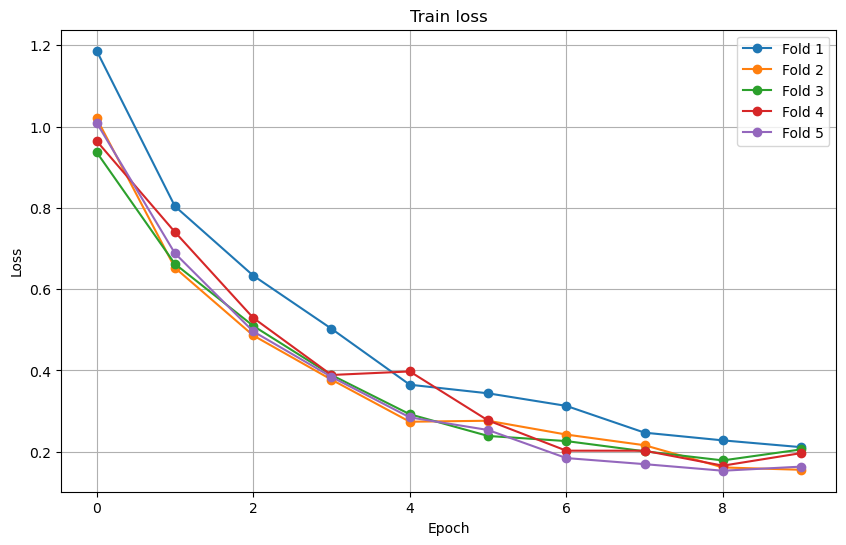

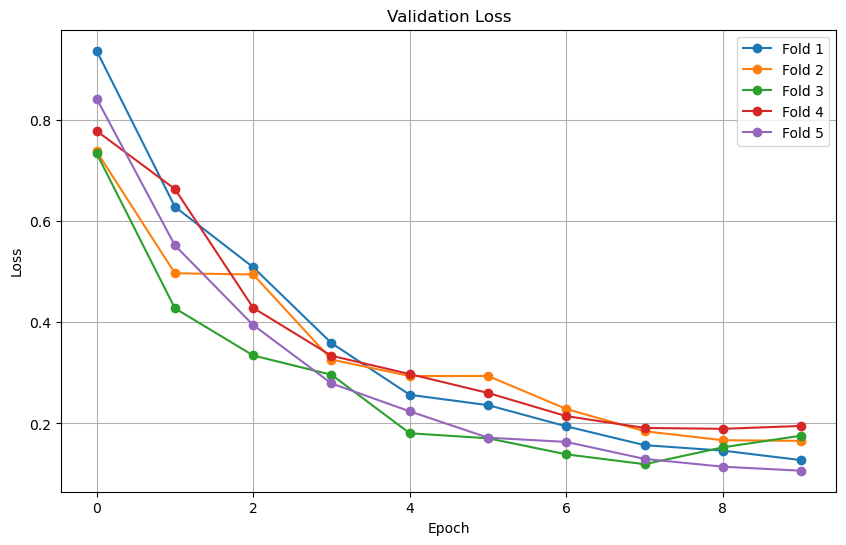

In [32]:
plt.figure(figsize=(10,6))
for i in range(NUM_FOLDS):
    plt.plot(all_fold_histories[i]['train_loss'],marker='o', label=f'Fold {i+1}')
plt.title('Train loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10,6))
for i in range(NUM_FOLDS):
    plt.plot(all_fold_histories[i]['val_loss'], marker = 'o', label=f'Fold {i+1}')
plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [33]:

# Save ONLY the best fold weights

best_checkpoint = os.path.join(
    CHECKPOINT_DIR,
    f"best_model_fold_{best_fold}.pth"
)

checkpoint = torch.load(best_checkpoint)

BEST_WEIGHT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_weights_cv.pth"
)

torch.save(
    checkpoint["model_state_dict"],
    BEST_WEIGHT_PATH
)

print(f"\nBest fold checkpoint : {best_checkpoint}")
print(f"Best weights saved   : {BEST_WEIGHT_PATH}")


Best fold checkpoint : checkpoints_old_34/best_model_fold_3.pth
Best weights saved   : checkpoints_old_34/best_weights_cv.pth


In [34]:
best_model_path =  f"/home/dbtproject/barsha/np_code_new/checkpoints_old_34/best_model_fold_{best_fold}.pth"
print(f"best model saved at: {best_model_path}")

best model saved at: /home/dbtproject/barsha/np_code_new/checkpoints_old_34/best_model_fold_3.pth


In [38]:
checkpoint = torch.load("/home/dbtproject/barsha/np_code_new/checkpoints_old_34/best_model_fold_1.pth")
print(checkpoint.keys())

dict_keys(['model_state_dict', 'optimizer_state_dict', 'epoch', 'val_accuracy', 'history'])


In [47]:
model = models.resnet34(weights = models.ResNet34_Weights.DEFAULT)
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, num_classes)

model.load_state_dict(torch.load(best_model_path)['model_state_dict'])
model.to(device)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [48]:
#testing phase
model.eval()
test_running_loss = 0.0
test_correct = 0
test_total = 0

all_test_preds = []
all_test_labels = []
test_bar = tqdm(test_loader, desc='Testing', leave=False)
with torch.no_grad():
    for inputs, labels in test_bar:
        inputs, labels = inputs.to(device), labels.to(device)
        batch_size = inputs.size(0)

        outputs = model(inputs.float())
        # Keep only Incognita and Javanica logits
        outputs = outputs[:, [1, 2]]
        labels = labels - 1
        loss = criterion(outputs, labels)

        test_running_loss += loss.item() * batch_size
        _, predicted = torch.max(outputs, 1)
        
        test_total += batch_size
        test_correct += (predicted == labels).sum().item()

        all_test_preds.extend(predicted.cpu().numpy())
        all_test_labels.extend(labels.cpu().numpy())

        test_bar.set_postfix(tloss=loss.item(), tacc=test_correct/test_total if test_total > 0 else 1)

ep_test_loss = test_running_loss / (test_total if test_total > 0 else 1)
ep_test_accuracy = test_correct / (test_total if test_total > 0 else 1)

print(f"Test Loss: {ep_test_loss:.4f} | Test Accuracy: {ep_test_accuracy:.4f}")
target_names=[
    "Class1_Incognita",
    "Class2_Javanica"
]

# Classification report
print("Classification Report:")
print(classification_report(all_test_labels, all_test_preds, digits = 4, target_names=target_names))     
# Confusion matrix
cm = confusion_matrix(all_test_labels, all_test_preds)
print("Confusion Matrix:")
print(cm)

Test Loss: 0.5234 | Test Accuracy: 0.7500
Classification Report:
                  precision    recall  f1-score   support

Class1_Incognita     0.7500    0.7500    0.7500        20
 Class2_Javanica     0.7500    0.7500    0.7500        20

        accuracy                         0.7500        40
       macro avg     0.7500    0.7500    0.7500        40
    weighted avg     0.7500    0.7500    0.7500        40

Confusion Matrix:
[[15  5]
 [ 5 15]]


In [49]:
import numpy as np

print("\nClass-wise Accuracy")

class_accuracy = cm.diagonal() / cm.sum(axis=1)

for i, acc in enumerate(class_accuracy):
    print(f"{target_names[i]} : {acc:.4f} ({acc*100:.2f}%)")


Class-wise Accuracy
Class1_Incognita : 0.7500 (75.00%)
Class2_Javanica : 0.7500 (75.00%)


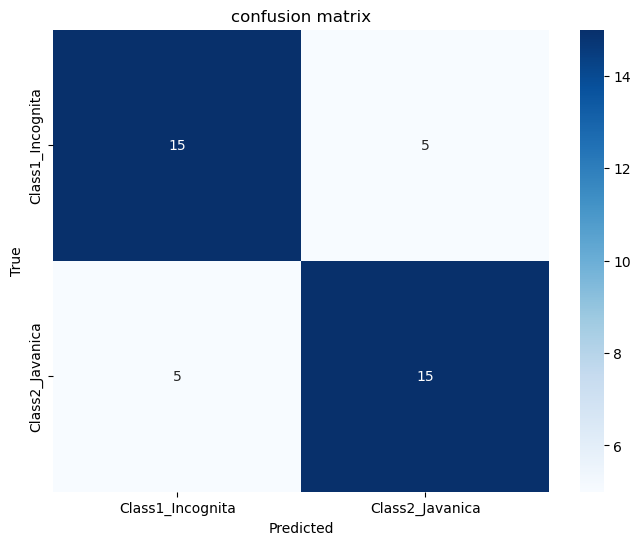

In [50]:
#confusion matrix plot
import seaborn as sns
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('confusion matrix')
plt.show()


In [51]:
#testing phase
model.eval()
test_running_loss = 0.0
test_correct = 0
test_total = 0

all_test_preds = []
all_test_labels = []
test_bar = tqdm(test_loader, desc='Testing', leave=False)
with torch.no_grad():
    for inputs, labels in test_bar:
        inputs, labels = inputs.to(device), labels.to(device)
        batch_size = inputs.size(0)

        outputs = model(inputs.float())
        loss = criterion(outputs, labels)

        test_running_loss += loss.item() * batch_size
        _, predicted = torch.max(outputs, 1)
        
        test_total += batch_size
        test_correct += (predicted == labels).sum().item()

        all_test_preds.extend(predicted.cpu().numpy())
        all_test_labels.extend(labels.cpu().numpy())

        test_bar.set_postfix(tloss=loss.item(), tacc=test_correct/test_total if test_total > 0 else 1)

ep_test_loss = test_running_loss / (test_total if test_total > 0 else 1)
ep_test_accuracy = test_correct / (test_total if test_total > 0 else 1)

print(f"Test Loss: {ep_test_loss:.4f} | Test Accuracy: {ep_test_accuracy:.4f}")

# Classification report
print("Classification Report:")
print(classification_report(all_test_labels, all_test_preds, digits = 4, target_names=le.classes_))     
# Confusion matrix
cm = confusion_matrix(all_test_labels, all_test_preds)
print("Confusion Matrix:")
print(cm)

/home/anaconda3/envs/new_env/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Test Loss: 0.9792 | Test Accuracy: 0.5000
Classification Report:


TypeError: object of type 'numpy.int64' has no len()

In [52]:
print(le.classes_)
print(le.classes_.dtype)

[0 1 2]
int64


In [38]:
mean_acc = np.mean(ep_val_accuracy)
std_acc  = np.std(ep_val_accuracy)

print(f"\nMean Val Accuracy: {mean_acc:.4f}")
print(f"Std Val Accuracy:  {std_acc:.4f}")


Mean Val Accuracy: 1.0000
Std Val Accuracy:  0.0000


In [39]:
# get labels as numpy array from train_df (the split)
# train_labels = train_df['label'].values
# classes, class_counts = np.unique(train_labels, return_counts=True)
# print("Classes:", classes)
# print("Class counts:", class_counts)

# # weight per class: inverse of count
# class_weights = {cls: 1.0 / count for cls, count in zip(classes, class_counts)}
# print("Class weights:", class_weights)

# # sample weight for each sample in the training split
# sample_weights = train_df['label'].map(class_weights).values  # pandas Series -> numpy

# # convert to torch tensor
# sample_weights_tensor = torch.from_numpy(sample_weights.astype(np.float32))

# # create WeightedRandomSampler
# num_samples = len(sample_weights_tensor)   # usually equals len(train_dataset)
# sampler = WeightedRandomSampler(weights=sample_weights_tensor, num_samples=num_samples, replacement=True)


In [40]:
BATCH_SIZE = 32
NUM_WORKERS = 4
PIN_MEMORY = True

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    sampler=sampler,  # use the weighted sampler
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

In [41]:
#configuration
NUM_FOLDS = 5
NUM_EPOCHS = 100
LR = 0.01
BATCH_SIZE = 32
GAMMA = 0.1
STEP_SIZE = 30
NUM_WORKERS = 4
CHECKPOINT_PATH = 'resnet50_best_model.pth'
os.makedirs(CHECKPOINT_PATH, exist_ok=True)


In [42]:
indices = np.arange(len(train_data))
indices

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

In [43]:
skf = StratifiedKFold(n_splits=NUM_FOLDS, shuffle=True, random_state=SEED)

In [44]:
cates=['Class0_Graminicola', 'Class1_Incognita', 'Class2_Javanica']
num_classes = len(cates)
num_classes

3

In [45]:
model = torchvision.models.resnet50(pretrained=True)

/home/anaconda3/envs/new_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/anaconda3/envs/new_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [46]:
model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [47]:
# import os
# import glob
# import random
# # Find image files recursively under the training path
# patterns = ['*.jpg', '*.jpeg', '*.png', '*.bmp', '*.tif', '*.tiff']
# image_paths = []
# for pat in patterns:
#     image_paths.extend(glob.glob(os.path.join(train_path, '**', pat), recursive=True))
# image_paths = sorted(set(image_paths))
# if not image_paths:
#     print(f'No image files found under {train_path!r}.')
#     try:
#         print('Contents of training directory:')
#         for entry in sorted(os.listdir(train_path)):
#             print('-', entry)
#     except Exception as e:
#         print('Could not list directory:', e)
# else:
#     n = min(2, len(image_paths))
#     sample_paths = image_paths[:n]  # use the first n images (or replace with random.sample)
#     fig, axes = plt.subplots(1, n, figsize=(6*n, 6))
#     if n == 1:
#         axes = [axes]
#     for ax, pth in zip(axes, sample_paths):
#         try:
#             img = Image.open(pth).convert('RGB')
#             ax.imshow(img)
#             ax.axis('off')
#             ax.set_title(os.path.relpath(pth, train_path))
#         except Exception as e:
#             ax.text(0.5, 0.5, f'Error opening\n{os.path.basename(pth)}:\n{e}', ha='center')
#             ax.axis('off')
#     plt.show()